# Projeto Avaliativo - Módulo 1: Análise de Dados de Viagens
**Aluna:** Viviane Bueno  
**Objetivo:** Análise exploratória e respostas às 7 perguntas de negócio utilizando a camada Silver do Data Lake e visualizações profissionais.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual e formatação de números
sns.set_theme(style="whitegrid")
pd.options.display.float_format = '{:,.2f}'.format

print("🚀 Bibliotecas carregadas com sucesso!")

🚀 Bibliotecas carregadas com sucesso!


In [18]:
# Carregar dados das tabelas Silver
df_viagem = pd.read_sql("SELECT * FROM public.silver_viagem;", engine)
df_pagamento = pd.read_sql("SELECT * FROM public.silver_pagamento;", engine)
df_trecho = pd.read_sql("SELECT * FROM public.silver_trecho;", engine)

# Limpar espaços nos nomes das colunas
df_viagem.columns = df_viagem.columns.str.strip()
df_pagamento.columns = df_pagamento.columns.str.strip()
df_trecho.columns = df_trecho.columns.str.strip()

# Função para converter valores monetários com segurança
def converter_para_float(val):
    if pd.isna(val):
        return 0.0
    if isinstance(val, (int, float)):
        return float(val)
    val_str = str(val).strip().replace('.', '').replace(',', '.')
    try:
        return float(val_str)
    except:
        return 0.0

# Aplicar conversões de custos
for col in ['valor_diarias', 'valor_passagens', 'valor_outros_gastos']:
    if col in df_viagem.columns:
        df_viagem[col] = df_viagem[col].apply(converter_para_float)

df_viagem['custo_total'] = df_viagem['valor_diarias'] + df_viagem['valor_passagens'] + df_viagem['valor_outros_gastos']

print("✅ Dados carregados e tratados com sucesso!")

✅ Dados carregados e tratados com sucesso!


C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:6: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.barplot(data=df_p1, x='nome_do_orgao_superior', y='custo_total', color='steelblue', hue='nome_do_orgao_superior', legend=False)


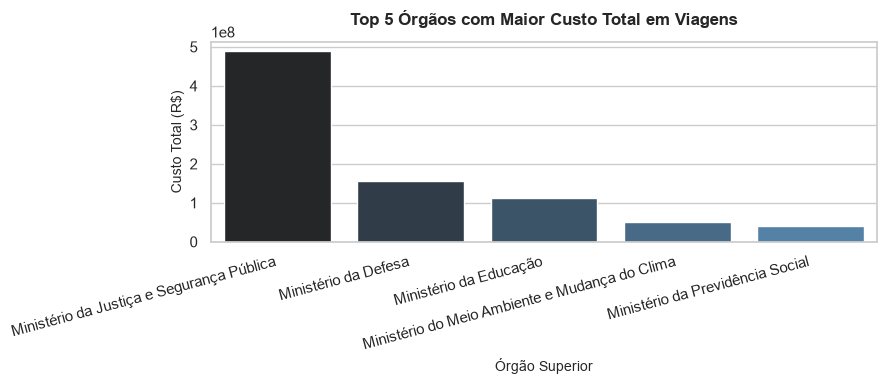

📋 Tabela - Pergunta 1:


,nome_do_orgao_superior,custo_total
11,Ministério da Justiça e Segurança Pública,"488,873,298.25"
5,Ministério da Defesa,"156,565,001.54"
6,Ministério da Educação,"111,905,403.15"
26,Ministério do Meio Ambiente e Mudança do Clima,"50,123,043.80"
13,Ministério da Previdência Social,"40,669,392.58"


C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:24: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:seagreen'` for the same effect.

  sns.barplot(data=df_p2, x='destinos', y='custo_medio_viagem', color='seagreen', hue='destinos', legend=False)
C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:28: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


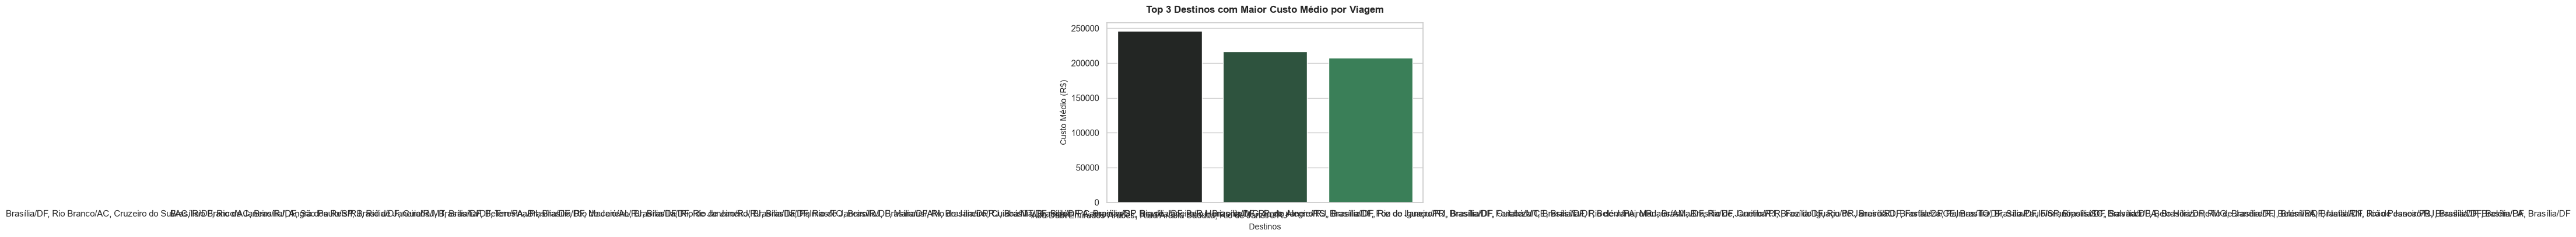

📋 Tabela - Pergunta 2:


,destinos,custo_medio_viagem
58,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita,...","245,852.80"
3878,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...","216,729.36"
3883,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis...","207,220.14"


🏆 Pergunta 3 - Viagem de Maior Duração:


,identificador_do_processo_de_viagem,nome,duracao_dias,custo_total
142430,0000000000020858185,JULIANI LUCINDA CALDEIRA FERREIRA,483.00,0.00


C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:57: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:darkorange'` for the same effect.

  sns.barplot(data=df_p4.head(5), x='tipo_pagamento', y='valor_medio', color='darkorange', hue='tipo_pagamento', legend=False)


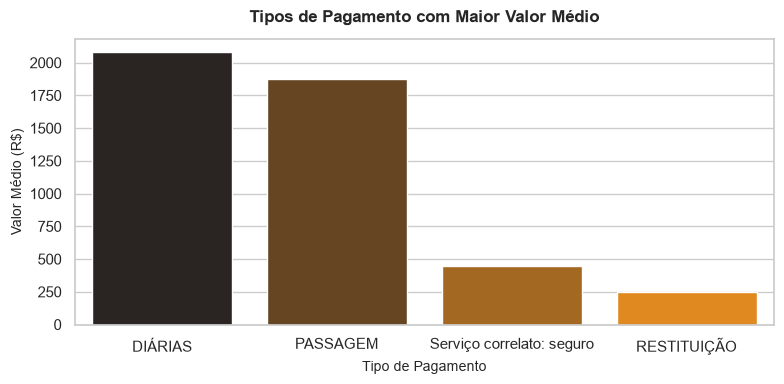

📋 Tabela - Pergunta 4:


,tipo_pagamento,valor_medio
0,DIÁRIAS,"2,078.28"
1,PASSAGEM,"1,878.34"
3,Serviço correlato: seguro,447.51
2,RESTITUIÇÃO,245.70


C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:74: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:mediumpurple'` for the same effect.

  sns.barplot(data=df_p5.head(5), x='meio_transporte', y='total_utilizacoes', color='mediumpurple', hue='meio_transporte', legend=False)


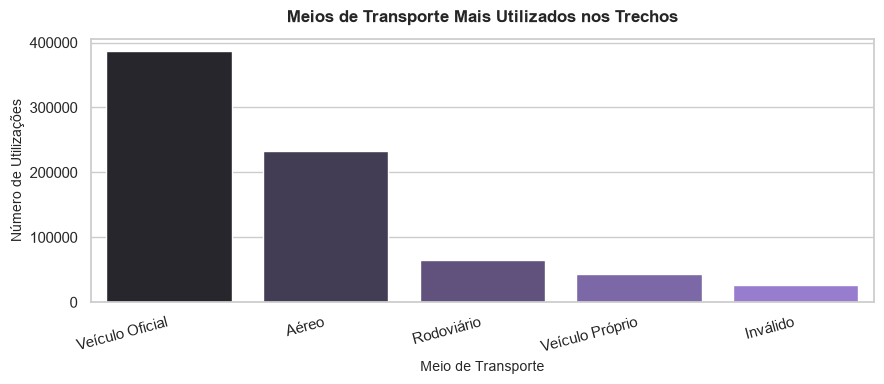

📋 Tabela - Pergunta 5:


,meio_transporte,total_utilizacoes
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


C:\Users\vivia\AppData\Local\Temp\ipykernel_21020\2947718987.py:92: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:teal'` for the same effect.

  sns.barplot(data=df_p6.head(5), x='destino_uf', y='total_trechos', color='teal', hue='destino_uf', legend=False)


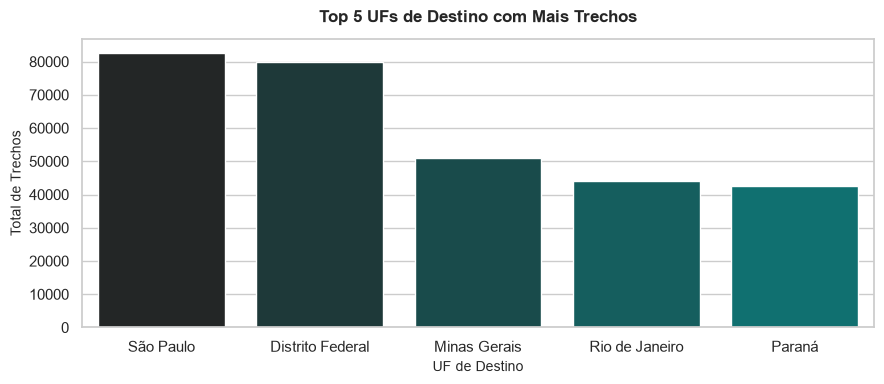

📋 Tabela - Pergunta 6:


,destino_uf,total_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


🏆 Pergunta 7 - Órgão que mais pagou no total:


,nome_do_orgao_superior,total_pago
11,Ministério da Justiça e Segurança Pública,"488,873,298.25"


In [19]:
# --- PERGUNTA 1: Top 5 Órgãos com Maior Custo Total ---
df_p1 = df_viagem.groupby('nome_do_orgao_superior')['custo_total'].sum().reset_index()
df_p1 = df_p1.dropna().sort_values(by='custo_total', ascending=False).head(5)

plt.figure(figsize=(9, 4))
sns.barplot(data=df_p1, x='nome_do_orgao_superior', y='custo_total', color='steelblue', hue='nome_do_orgao_superior', legend=False)
plt.title('Top 5 Órgãos com Maior Custo Total em Viagens', fontsize=12, weight='bold', pad=12)
plt.xlabel('Órgão Superior', fontsize=10)
plt.ylabel('Custo Total (R$)', fontsize=10)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()
print("📋 Tabela - Pergunta 1:")
display(df_p1)


# --- PERGUNTA 2: Top 3 Destinos com Maior Custo Médio por Viagem ---
df_p2 = df_viagem.groupby('destinos')['custo_total'].mean().reset_index()
df_p2 = df_p2[df_p2['destinos'].notna() & (df_p2['destinos'] != '')]
df_p2 = df_p2.sort_values(by='custo_total', ascending=False).head(3)
df_p2.rename(columns={'custo_total': 'custo_medio_viagem'}, inplace=True)

plt.figure(figsize=(7, 4))
sns.barplot(data=df_p2, x='destinos', y='custo_medio_viagem', color='seagreen', hue='destinos', legend=False)
plt.title('Top 3 Destinos com Maior Custo Médio por Viagem', fontsize=12, weight='bold', pad=12)
plt.xlabel('Destinos', fontsize=10)
plt.ylabel('Custo Médio (R$)', fontsize=10)
plt.tight_layout()
plt.show()
print("📋 Tabela - Pergunta 2:")
display(df_p2)


# --- PERGUNTA 3: Viagem de Maior Duração e seu Custo Total ---
col_inicio = [c for c in df_viagem.columns if 'inicio' in c.lower()][0]
col_fim = [c for c in df_viagem.columns if 'fim' in c.lower()][0]
df_viagem[col_inicio] = pd.to_datetime(df_viagem[col_inicio], errors='coerce')
df_viagem[col_fim] = pd.to_datetime(df_viagem[col_fim], errors='coerce')
df_viagem['duracao_dias'] = (df_viagem[col_fim] - df_viagem[col_inicio]).dt.days

df_p3 = df_viagem.dropna(subset=['duracao_dias']).sort_values(by='duracao_dias', ascending=False).head(1)
df_p3_final = df_p3[['identificador_do_processo_de_viagem', 'nome', 'duracao_dias', 'custo_total']]
print("🏆 Pergunta 3 - Viagem de Maior Duração:")
display(df_p3_final)


# --- PERGUNTA 4: Tipo de Pagamento com Maior Valor Médio ---
col_tipo_pag = [c for c in df_pagamento.columns if 'tipo' in c.lower() or 'pagamento' in c.lower()][0]
col_val_pag = [c for c in df_pagamento.columns if 'valor' in c.lower()][0]
df_pagamento[col_val_pag] = df_pagamento[col_val_pag].apply(converter_para_float)

df_p4 = df_pagamento.groupby(col_tipo_pag)[col_val_pag].mean().reset_index()
df_p4.columns = ['tipo_pagamento', 'valor_medio']
df_p4 = df_p4.dropna().sort_values(by='valor_medio', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=df_p4.head(5), x='tipo_pagamento', y='valor_medio', color='darkorange', hue='tipo_pagamento', legend=False)
plt.title('Tipos de Pagamento com Maior Valor Médio', fontsize=12, weight='bold', pad=12)
plt.xlabel('Tipo de Pagamento', fontsize=10)
plt.ylabel('Valor Médio (R$)', fontsize=10)
plt.tight_layout()
plt.show()
print("📋 Tabela - Pergunta 4:")
display(df_p4)


# --- PERGUNTA 5: Meio de Transporte mais usado nos trechos ---
col_transporte = [c for c in df_trecho.columns if 'transporte' in c.lower()][0]
df_p5 = df_trecho[col_transporte].value_counts().reset_index()
df_p5.columns = ['meio_transporte', 'total_utilizacoes']
df_p5 = df_p5.dropna()

plt.figure(figsize=(9, 4))
sns.barplot(data=df_p5.head(5), x='meio_transporte', y='total_utilizacoes', color='mediumpurple', hue='meio_transporte', legend=False)
plt.title('Meios de Transporte Mais Utilizados nos Trechos', fontsize=12, weight='bold', pad=12)
plt.xlabel('Meio de Transporte', fontsize=10)
plt.ylabel('Número de Utilizações', fontsize=10)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()
print("📋 Tabela - Pergunta 5:")
display(df_p5)


# --- PERGUNTA 6: UF de Destino com mais trechos ---
col_uf_dest = [c for c in df_trecho.columns if 'uf' in c.lower() and ('destino' in c.lower() or 'dest' in c.lower())][0]
df_p6 = df_trecho[col_uf_dest].value_counts().reset_index()
df_p6.columns = ['destino_uf', 'total_trechos']
df_p6 = df_p6.dropna()

plt.figure(figsize=(9, 4))
sns.barplot(data=df_p6.head(5), x='destino_uf', y='total_trechos', color='teal', hue='destino_uf', legend=False)
plt.title('Top 5 UFs de Destino com Mais Trechos', fontsize=12, weight='bold', pad=12)
plt.xlabel('UF de Destino', fontsize=10)
plt.ylabel('Total de Trechos', fontsize=10)
plt.tight_layout()
plt.show()
print("📋 Tabela - Pergunta 6:")
display(df_p6)


# --- PERGUNTA 7: Órgão que mais pagou no total ---
df_p7 = df_viagem.groupby('nome_do_orgao_superior')['custo_total'].sum().reset_index()
df_p7 = df_p7.dropna().sort_values(by='custo_total', ascending=False).head(1)
df_p7.rename(columns={'custo_total': 'total_pago'}, inplace=True)
print("🏆 Pergunta 7 - Órgão que mais pagou no total:")
display(df_p7)